# K-K Consistency of the Predictions

Two properties of the held-out predictions are measured: the K-K residual $\rho$ and the sign
errors of the predicted $\mathrm{Im}\,Z$. The models are GP-RBF-0, GP-RBF-c, K-K GP-0 and
K-K GP-ECM. Further sections give the error floor of the constraint and the predictions at the D3
state $v = 3.2261$. The last section fits GP-RBF-0 at that state again from several starts. The
fits use the settings of notebook 02. With the output files in `experiments/` a run takes a few
seconds. Computing everything again takes about 32 min with `N_JOBS = 3`.

In [1]:
%matplotlib inline
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from eis import consistency, data, datasets, env, utils
from eis.plotting import COL, apply_style

RECOMPUTE = False   # True computes every output file again
N_JOBS = 3          # number of worker processes for the fits
# folder of the output files (experiments/ in the repository root)
OUT = os.path.join(env.DIR_BASE, "experiments")
os.makedirs(OUT, exist_ok=True)

# PyTorch warns that a tensor made from a read-only NumPy array must not be written. The models
# only read these tensors. PYTHONWARNINGS passes the same filter to the worker processes.
warnings.filterwarnings("ignore", message="The given NumPy array is not writable")
os.environ["PYTHONWARNINGS"] = "ignore:The given NumPy array is not writable:UserWarning"

DATA = {name: data.load_dataset(name) for name in datasets.DATASETS}
CASES = utils.held_out_cases(DATA)


apply_style()

## Sign Errors and the K-K Residual

A held-out frequency has a sign error when the predicted and the measured $\mathrm{Im}\,Z$ have
opposite signs. A state counts under "any" when at least one of its frequencies has a sign
error. It counts under "majority" when more than half of its frequencies have one. The K-K
residual of a held-out prediction $\hat{Z}$ about the mean $\mathbf{m}$ of its model is

$$\rho = \frac{\lVert(\mathrm{Im}\,\hat{Z} - m_\mathrm{im}) - \mathbf{H}(\mathrm{Re}\,\hat{Z}
- m_\mathrm{re})\rVert_2}{\lVert\mathrm{Im}\,\hat{Z} - m_\mathrm{im}\rVert_2}.$$

Here $\mathbf{H}$ is the discrete Hilbert transform on the frequencies of the held-out state. The
residual is zero when the prediction satisfies the discrete K-K relation about its mean. The
mean is zero for GP-RBF-0 and K-K GP-0. It is the fitted constant $(c_\mathrm{re}, c_\mathrm{im})$
for GP-RBF-c and the circuit for K-K GP-ECM. Since $\mathbf{H}\mathbf{1} = \mathbf{0}$, the
constant $c_\mathrm{re}$ drops out of $\rho$. The output files hold $\rho$ in the column
`kk_rel_resid` (`kk_rel_resid_const_frame` for GP-RBF-c). The columns `any_wrong_sign` and
`majority_wrong_sign` mark the states that count under "any" and "majority".

In [2]:
def compute_sign_errors():
    cases = [(name, s, label, df) for name, s, df in CASES for label in consistency.MODELS]
    three = utils.fit_parallel(consistency.sign_errors, cases, N_JOBS)
    three = three.sort_values(["method", "dataset", "held_out_v"]).reset_index(drop=True)
    circuit = utils.fit_parallel(consistency.sign_errors_kkgp_ecm, CASES, N_JOBS)
    return pd.concat([three, circuit], ignore_index=True)


signs = utils.load_or_compute(
    os.path.join(OUT, "03_sign_errors.csv"), compute_sign_errors, RECOMPUTE)
rho_c = utils.load_or_compute(
    os.path.join(OUT, "03_rho_gp_rbf_c.csv"),
    lambda: utils.fit_parallel(consistency.rho_gp_rbf_c, CASES, N_JOBS), RECOMPUTE)

93 fits in 12.3 min


[2026-10-19 06:30:19][WAR] KKGP LBFGS step aborted (_LinAlgError); keeping best params.


31 fits in 10.7 min


31 fits in 1.8 min


In [3]:
MEANS = {"GP-RBF-0": "zero", "GP-RBF-c": "constant", "K-K GP-0": "zero", "K-K GP-ECM": "circuit"}
rows = []
for model, mean in MEANS.items():
    s = signs[signs["method"] == model]
    rho = rho_c["kk_rel_resid_const_frame"] if model == "GP-RBF-c" else s["kk_rel_resid"]
    rows.append({
        "model": model,
        "mean": mean,
        "median rho": rho.median(),
        "any": f"{int(s['any_wrong_sign'].sum())}/{len(s)}",
        "majority": f"{int(s['majority_wrong_sign'].sum())}/{len(s)}",
    })
table = pd.DataFrame(rows).set_index("model")
table["median rho"] = table["median rho"].map(lambda x: f"{x:.2f}" if x > 1e-3 else f"{x:.0e}")
table

,mean,median rho,any,majority
model,,,,
GP-RBF-0,zero,0.54,10/31,3/31
GP-RBF-c,constant,1.02,12/31,1/31
K-K GP-0,zero,4e-16,12/31,2/31
K-K GP-ECM,circuit,7e-15,5/31,0/31


The same fits give three more results. The first is the number of states with $\rho > 0.1$ for
the two unconstrained models. The second is the largest $\rho$ of the two constrained models. The
last table counts the states with a sign error in each region.

In [4]:
rho_0 = signs.loc[signs["method"] == "GP-RBF-0", "kk_rel_resid"]
rho_const = rho_c["kk_rel_resid_const_frame"]
print(f"States with rho > 0.1: GP-RBF-0 {int((rho_0 > 0.1).sum())} of {len(rho_0)}, "
      f"GP-RBF-c {int((rho_const > 0.1).sum())} of {len(rho_const)}")
constrained = signs.loc[signs["method"].isin(["K-K GP-0", "K-K GP-ECM"]), "kk_rel_resid"]
print(f"Largest rho of K-K GP-0 and K-K GP-ECM: {constrained.max():.1e}")

print("\nStates with a sign error in each region:")
regions = {}
for model in MEANS:
    s = signs[signs["method"] == model]
    regions[model] = {f"{d.split('_')[0]} {r}":
                      f"{int(g['any_wrong_sign'].sum())}/{len(g)}"
                      for (d, r), g in s.groupby(["dataset", "region"])}
print(pd.DataFrame(regions).T[[f"{d.split('_')[0]} {r}" for d, r in utils.REGIONS]].to_string())

States with rho > 0.1: GP-RBF-0 31 of 31, GP-RBF-c 31 of 31
Largest rho of K-K GP-0 and K-K GP-ECM: 3.6e-14

States with a sign error in each region:
           D1 interior D1 boundary D2 interior D2 boundary D3 interior D3 boundary
GP-RBF-0           0/4         1/2         3/3         2/2        2/18         2/2
GP-RBF-c           3/4         1/2         3/3         2/2        2/18         1/2
K-K GP-0           4/4         2/2         3/3         2/2        0/18         1/2
K-K GP-ECM         0/4         0/2         3/3         2/2        0/18         0/2


## Error Floor of the Constraint

Let $\mathbf{m}$ be a mean on the $n_\omega$ frequencies of one state. Every prediction of a
constrained model with this mean lies in the set

$$A(\mathbf{m}) = \{(m_\mathrm{re} + \mathbf{u},\ m_\mathrm{im} + \mathbf{H}\mathbf{u}) :
\mathbf{u} \in \mathbb{R}^{n_\omega}\}.$$

Let $\mathbf{y} = (\mathbf{y}_\mathrm{re}, \mathbf{y}_\mathrm{im})$ be the measured spectrum and
$\mathbf{r} = \mathbf{y} - \mathbf{m}$. The point of $A(\mathbf{m})$ closest to $\mathbf{y}$ solves

$$(\mathbf{I} + \mathbf{H}^\top\mathbf{H})\,\mathbf{u} = \mathbf{r}_\mathrm{re}
+ \mathbf{H}^\top\mathbf{r}_\mathrm{im}.$$

Its imaginary error $\mathbf{e}_\mathrm{im} = \mathbf{r}_\mathrm{im} - \mathbf{H}\mathbf{u}$ gives
the floor. A constrained predictor with this mean has a smaller imaginary error only with a
larger real error. The floor is computed for three means. The first two are zero and the
constant $(c_\mathrm{re}, c_\mathrm{im})$ that brings $A(\mathbf{m})$ closest to $\mathbf{y}$. The
third is the circuit mean of K-K GP-ECM with the state held out. The table averages the RMS of
$\mathbf{e}_\mathrm{im}$ over the states of each dataset. The gain is the zero-mean floor divided
by the circuit-mean floor. The column rms Im Z gives the RMS of $\mathbf{y}_\mathrm{im}$ with the
same averaging. The last column counts the states at which K-K GP-ECM has a sign error. The floors come from `eis.consistency.error_floor_rows` with
`floor_zero_or_ecm` and `floor_constant`.

In [5]:
floor = utils.load_or_compute(
    os.path.join(OUT, "03_error_floor.csv"), consistency.error_floor_rows, RECOMPUTE)

rows = []
for name in datasets.DATASETS:
    f = floor[floor["dataset"] == name]
    m = f.groupby("mean")["floor_im_rms"].mean()
    s = signs[(signs["method"] == "K-K GP-ECM") & (signs["dataset"] == name)]
    rows.append({
        "dataset": name.split("_")[0],
        "rms Im Z": f"{f[f['mean'] == 'zero']['yim_rms'].mean():.3g}",
        "zero": utils.two_digits(m["zero"]),
        "const.": utils.two_digits(m["constant"]),
        "circuit": utils.two_digits(m["ecm"]),
        "gain": f"{m['zero'] / m['ecm']:.1f}x",
        "K-K GP-ECM sign errors": f"{int(s['any_wrong_sign'].sum())}/{len(s)}",
    })
pd.DataFrame(rows).set_index("dataset")

,rms Im Z,zero,const.,circuit,gain,K-K GP-ECM sign errors
dataset,,,,,,
D1,0.196,0.039,0.037,0.011,3.6x,0/6
D2,0.00852,0.0036,0.0035,0.0041,0.9x,5/5
D3,0.0234,0.0083,0.0072,0.0026,3.2x,0/20


## Prediction at the D3 State v = 3.2261

At this state GP-RBF-0 has the largest share of frequencies with a sign error of all 31 states.
The figure shows the measured spectrum and the held-out predictions of K-K GP-0 and GP-RBF-0. It
plots $-\mathrm{Im}\,Z$ against $\mathrm{Re}\,Z$ (the Nyquist plane). Both models have the zero
mean and are fitted on the other 19 states of D3. Their predicted means at the 28 frequencies of
the state come from `eis.consistency.signflip_arrays`.

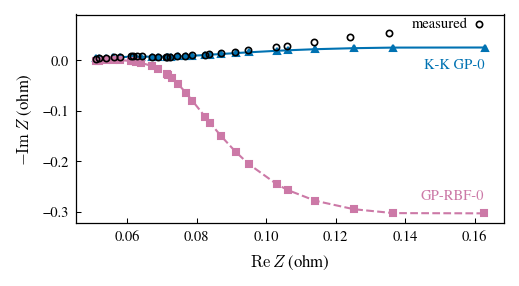

In [6]:
SIGNFLIP_FILE = os.path.join(OUT, "03_signflip.npz")
if RECOMPUTE or not os.path.isfile(SIGNFLIP_FILE):
    np.savez(SIGNFLIP_FILE, **consistency.signflip_arrays())
flip = np.load(SIGNFLIP_FILE)
zr, zi = flip["zr"], flip["zi"]

fig, ax = plt.subplots(figsize=(COL, 1.95))
ax.plot(flip["kk_re"], -flip["kk_im"], "^-", ms=3, lw=1.0, color="#0072B2")
ax.plot(flip["gp_re"], -flip["gp_im"], "s--", ms=3, lw=1.0, color="#CC79A7")
ax.plot(zr, -zi, "o", ms=3, mfc="none", mec="black", mew=0.8)
# each label sits beside the point of its curve at the lowest frequency
i = int(np.argmin(flip["logf"]))
ax.annotate("measured", (zr[i], -zi[i]), xytext=(-5, 0), textcoords="offset points",
            ha="right", va="center", color="black", fontsize=7)
ax.annotate("K-K GP-0", (flip["kk_re"][i], -flip["kk_im"][i]), xytext=(0, -5),
            textcoords="offset points", ha="right", va="top", color="#0072B2", fontsize=7)
ax.annotate("GP-RBF-0", (flip["gp_re"][i], -flip["gp_im"][i]), xytext=(0, 5),
            textcoords="offset points", ha="right", va="bottom", color="#CC79A7", fontsize=7)
ax.set_xlabel(r"$\mathrm{Re}\,Z$ (ohm)")
ax.set_ylabel(r"$-\mathrm{Im}\,Z$ (ohm)")
fig.tight_layout()

In [7]:
n_wrong = int((np.sign(flip["gp_im"]) != np.sign(zi)).sum())
print(f"GP-RBF-0: Im Z with the wrong sign at {n_wrong} of {zi.size} frequencies, "
      f"largest predicted Im Z {flip['gp_im'].max():.2f} ohm")
print(f"Measured Im Z: from {zi.min():.3f} to {zi.max():.4f} ohm")
for label, key in [("K-K GP-0", "kk"), ("GP-RBF-0", "gp")]:
    rmse_re = np.sqrt(np.mean((flip[f"{key}_re"] - zr) ** 2))
    rmse_im = np.sqrt(np.mean((flip[f"{key}_im"] - zi) ** 2))
    print(f"{label}: RMSE Re {rmse_re:.4f} ohm, RMSE Im {rmse_im:.3f} ohm")

GP-RBF-0: Im Z with the wrong sign at 25 of 28 frequencies, largest predicted Im Z 0.30 ohm
Measured Im Z: from -0.071 to -0.0028 ohm
K-K GP-0: RMSE Re 0.0005 ohm, RMSE Im 0.012 ohm
GP-RBF-0: RMSE Re 0.0005 ohm, RMSE Im 0.170 ohm


## Optimizer Restarts

The inverted imaginary channel of GP-RBF-0 at this state could come from a poor local optimum of
the marginal likelihood. To test this, `eis.consistency.restart_rows` fits GP-RBF-0 again from
nine starts. The first is the default start with all length scales 1. The other eight set the
length scale of $v$ in both channels to 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5 or 1.0. For each
start the table lists the final negative log marginal likelihood and the imaginary RMSE. It also
gives the number of frequencies with a predicted $\mathrm{Im}\,Z > 0$. The last column is the
fitted length scale of $v$ in the imaginary channel. Every measured $\mathrm{Im}\,Z$ of this state
is negative.

In [8]:
restarts = utils.load_or_compute(
    os.path.join(OUT, "03_restarts.csv"), consistency.restart_rows, RECOMPUTE)
print(restarts.to_string(index=False, formatters={
    "nll_final": "{:.3f}".format, "rmse_im": "{:.4f}".format, "ls_v_im": "{:.4f}".format}))
best = restarts.loc[restarts["nll_final"].idxmin()]
print(f"\nSmallest negative log marginal likelihood: start {best['start']}, "
      f"{int(best['n_im_positive'])} of {zi.size} frequencies with predicted Im Z > 0")

     start nll_final rmse_im  n_im_positive ls_v_im
   default -5887.200  0.1703             25  0.0209
ls_v=0.005 -5887.198  0.1681             25  0.0209
 ls_v=0.01 -5887.202  0.1694             25  0.0209
 ls_v=0.02 -5887.193  0.1694             25  0.0209
 ls_v=0.05 -5812.991  0.0022              0  0.0545
  ls_v=0.1 -5812.993  0.0022              0  0.0545
  ls_v=0.2 -5812.991  0.0022              0  0.0545
  ls_v=0.5 -5887.201  0.1698             25  0.0209
  ls_v=1.0 -5887.200  0.1703             25  0.0209

Smallest negative log marginal likelihood: start ls_v=0.01, 25 of 28 frequencies with predicted Im Z > 0
